In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    balanced_accuracy_score
)
from imblearn.over_sampling import RandomOverSampler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
current_path = Path.cwd()
possible_roots = [current_path, *current_path.parents]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (
            path / "data" / "gerrit" /
            "couchbase_java_client" / "features"
        ).exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Open this notebook from the project directory."
    )

DATA_PATH = (
    PROJECT_ROOT / "data" / "gerrit" / "couchbase_java_client"
    / "features" / "gerrit_structured_features.csv"
)

DIFF_PATH = (
    PROJECT_ROOT / "data" / "gerrit" / "couchbase_java_client"
    / "processed" / "finalized_gerrit.csv"
)

features_df = pd.read_csv(DATA_PATH)
diff_df = pd.read_csv(DIFF_PATH)

print("Project root:", PROJECT_ROOT)
print("Structured features:", features_df.shape)
print("Original Gerrit dataset:", diff_df.shape)

print("\nFiles loaded successfully.")

Project root: /Users/mustafaahmed/Documents/Security Code Review Analysis
Structured features: (2635, 34)
Original Gerrit dataset: (2635, 14)

Files loaded successfully.


In [3]:
KEY_COLUMNS = ["review_number", "revision_number"]

df = features_df.merge(
    diff_df[KEY_COLUMNS + ["code_diff"]],
    on=KEY_COLUMNS,
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", df.shape)
print("Non-empty code diffs:", df["code_diff"].notna().sum())
print(
    "Empty code diffs:",
    df["code_diff"].isna().sum()
    + (df["code_diff"].astype(str).str.strip() == "").sum()
)

print("\nLabel distribution:")
print(df["security_label"].value_counts().sort_index())

Merged dataset shape: (2635, 35)
Non-empty code diffs: 1774
Empty code diffs: 861

Label distribution:
security_label
0      85
1    2550
Name: count, dtype: int64


In [4]:
df["code_diff"] = df["code_diff"].fillna("").astype(str)

df_model = df[
    df["code_diff"].str.strip().ne("")
].copy()

df_model["security_label"] = df_model["security_label"].astype(int)

print("Modelling dataset shape:", df_model.shape)

print("\nTarget distribution:")
print(df_model["security_label"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df_model["security_label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nUnique reviews:", df_model["review_number"].nunique())

majority_count = (df_model["security_label"] == 1).sum()
minority_count = (df_model["security_label"] == 0).sum()

print(
    "\nMajority-to-minority ratio:",
    round(majority_count / minority_count, 2)
)

Modelling dataset shape: (1774, 35)

Target distribution:
security_label
0      71
1    1703
Name: count, dtype: int64

Target percentages:
security_label
1    96.0
0     4.0
Name: proportion, dtype: float64

Unique reviews: 808

Majority-to-minority ratio: 23.99


In [5]:
TARGET = "security_label"

# TF-IDF will be extracted from the actual code diffs.
TEXT_COLUMN = "code_diff"

# Structured features retained after the ablation experiment.
STRUCTURED_FEATURES = [
    "diff_character_count",
    "diff_line_count",
    "added_line_count",
    "deleted_line_count",
    "changed_file_count_from_diff",
    "java_file_count",
    "test_file_count",
    "unique_file_extension_count",
    "java_file_indicator",
    "conditional_count",
    "loop_count",
    "exception_count",
    "method_declaration_count",
    "review_message_count",
    "review_message_character_count",
    "changed_files",
    "insertions",
    "deletions"
]

missing_features = [
    col for col in STRUCTURED_FEATURES
    if col not in df_model.columns
]

if missing_features:
    raise ValueError(
        f"Missing structured features: {missing_features}"
    )

print("Structured feature count:", len(STRUCTURED_FEATURES))
print("Structured features:")
print(STRUCTURED_FEATURES)

Structured feature count: 18
Structured features:
['diff_character_count', 'diff_line_count', 'added_line_count', 'deleted_line_count', 'changed_file_count_from_diff', 'java_file_count', 'test_file_count', 'unique_file_extension_count', 'java_file_indicator', 'conditional_count', 'loop_count', 'exception_count', 'method_declaration_count', 'review_message_count', 'review_message_character_count', 'changed_files', 'insertions', 'deletions']


In [6]:
X = df_model[STRUCTURED_FEATURES].copy()
y = df_model[TARGET].copy()
groups = df_model["review_number"].copy()
texts = df_model[TEXT_COLUMN].copy()

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation configured.")
print("Number of folds: 5")
print("Unique review groups:", groups.nunique())

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    train_groups = set(groups.iloc[train_idx])
    valid_groups = set(groups.iloc[valid_idx])

    print(
        f"Fold {fold_number}: "
        f"Training rows={len(train_idx)}, "
        f"Validation rows={len(valid_idx)}, "
        f"Training positives={(y.iloc[train_idx] == 0).sum()}, "
        f"Validation positives={(y.iloc[valid_idx] == 0).sum()}, "
        f"Overlapping reviews={len(train_groups & valid_groups)}"
    )

Cross-validation configured.
Number of folds: 5
Unique review groups: 808
Fold 1: Training rows=1419, Validation rows=355, Training positives=57, Validation positives=14, Overlapping reviews=0
Fold 2: Training rows=1419, Validation rows=355, Training positives=57, Validation positives=14, Overlapping reviews=0
Fold 3: Training rows=1421, Validation rows=353, Training positives=58, Validation positives=13, Overlapping reviews=0
Fold 4: Training rows=1416, Validation rows=358, Training positives=55, Validation positives=16, Overlapping reviews=0
Fold 5: Training rows=1421, Validation rows=353, Training positives=57, Validation positives=14, Overlapping reviews=0


In [7]:
EXPERIMENTS = [
    {
        "name": "TF-IDF + Random Oversampling",
        "feature_set": "TF-IDF",
        "strategy": "Random oversampling"
    },
    {
        "name": "Combined 18 Features + Random Oversampling",
        "feature_set": "Combined",
        "strategy": "Random oversampling"
    },
    {
        "name": "Combined 18 Features + Class Weighting",
        "feature_set": "Combined",
        "strategy": "Class weighting"
    },
    {
        "name": "Structured 18 Features + Random Oversampling",
        "feature_set": "Structured",
        "strategy": "Random oversampling"
    }
]

for experiment in EXPERIMENTS:
    print(experiment["name"])

TF-IDF + Random Oversampling
Combined 18 Features + Random Oversampling
Combined 18 Features + Class Weighting
Structured 18 Features + Random Oversampling


In [8]:
def prepare_structured_features(X_train, X_valid):
    imputer = SimpleImputer(strategy="median")

    train_imputed = imputer.fit_transform(X_train)
    valid_imputed = imputer.transform(X_valid)

    scaler = StandardScaler()

    train_scaled = scaler.fit_transform(train_imputed)
    valid_scaled = scaler.transform(valid_imputed)

    return train_scaled, valid_scaled


def prepare_tfidf_features(text_train, text_valid):
    vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        stop_words="english"
    )

    train_tfidf = vectorizer.fit_transform(text_train)
    valid_tfidf = vectorizer.transform(text_valid)

    return train_tfidf, valid_tfidf


def evaluate_model(y_true, predictions, probabilities):
    return {
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "PR_AUC": average_precision_score(
            y_true, probabilities
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        )
    }

In [9]:
results = []

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    print(f"Processing fold {fold_number}...")

    X_train_struct = X.iloc[train_idx]
    X_valid_struct = X.iloc[valid_idx]

    text_train = texts.iloc[train_idx]
    text_valid = texts.iloc[valid_idx]

    y_train = (y.iloc[train_idx] == 0).astype(int)
    y_valid = (y.iloc[valid_idx] == 0).astype(int)

    # Preprocess structured features within this fold.
    structured_train, structured_valid = (
        prepare_structured_features(
            X_train_struct,
            X_valid_struct
        )
    )

    # Extract TF-IDF features within this fold.
    tfidf_train, tfidf_valid = prepare_tfidf_features(
        text_train,
        text_valid
    )

    # Build combined feature matrices.
    from scipy.sparse import csr_matrix, hstack

    combined_train = hstack([
        tfidf_train,
        csr_matrix(structured_train)
    ]).tocsr()

    combined_valid = hstack([
        tfidf_valid,
        csr_matrix(structured_valid)
    ]).tocsr()

    for experiment in EXPERIMENTS:

        feature_set = experiment["feature_set"]
        strategy = experiment["strategy"]

        if feature_set == "TF-IDF":
            X_train_current = tfidf_train
            X_valid_current = tfidf_valid

        elif feature_set == "Combined":
            X_train_current = combined_train
            X_valid_current = combined_valid

        elif feature_set == "Structured":
            X_train_current = structured_train
            X_valid_current = structured_valid

        else:
            raise ValueError("Unknown feature set.")

        # Apply balancing only to training data.
        if strategy == "Random oversampling":
            sampler = RandomOverSampler(random_state=42)

            X_fit, y_fit = sampler.fit_resample(
                X_train_current,
                y_train
            )

            model = LogisticRegression(
                max_iter=2000,
                random_state=42
            )

        elif strategy == "Class weighting":
            X_fit = X_train_current
            y_fit = y_train

            model = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )

        else:
            raise ValueError("Unknown imbalance strategy.")

        model.fit(X_fit, y_fit)

        predictions = model.predict(X_valid_current)
        probabilities = model.predict_proba(
            X_valid_current
        )[:, 1]

        metrics = evaluate_model(
            y_valid,
            predictions,
            probabilities
        )

        results.append({
            "Fold": fold_number,
            "Model": experiment["name"],
            "Feature Set": feature_set,
            "Imbalance Strategy": strategy,
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "F1": metrics["F1"],
            "PR_AUC": metrics["PR_AUC"],
            "Balanced Accuracy": metrics["Balanced Accuracy"]
        })

print("\nAll model experiments completed.")

Processing fold 1...
Processing fold 2...
Processing fold 3...
Processing fold 4...
Processing fold 5...

All model experiments completed.


In [10]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Model", "Fold"]
    ).round(4)
)

,Fold,Model,Feature Set,Imbalance Strategy,Precision,Recall,F1,PR_AUC,Balanced Accuracy
2,1,Combined 18 Features + Class Weighting,Combined,Class weighting,0.2632,0.3571,0.3030,0.2244,0.6580
6,2,Combined 18 Features + Class Weighting,Combined,Class weighting,0.3636,0.2857,0.3200,0.2554,0.6326
10,3,Combined 18 Features + Class Weighting,Combined,Class weighting,0.2105,0.3077,0.2500,0.2122,0.6318
14,4,Combined 18 Features + Class Weighting,Combined,Class weighting,0.2963,0.5000,0.3721,0.5066,0.7222
18,5,Combined 18 Features + Class Weighting,Combined,Class weighting,0.2632,0.3571,0.3030,0.3449,0.6579
1,1,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.2632,0.3571,0.3030,0.2661,0.6580
5,2,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.4444,0.2857,0.3478,0.2704,0.6355
9,3,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.3125,0.3846,0.3448,0.2357,0.6761
13,4,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.2963,0.5000,0.3721,0.5061,0.7222
17,5,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.2500,0.3571,0.2941,0.3514,0.6564


In [11]:
summary_df = (
    results_df
    .groupby(
        ["Model", "Feature Set", "Imbalance Strategy"]
    )
    .agg(
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_F1=("F1", "mean"),
        Mean_PR_AUC=("PR_AUC", "mean"),
        Std_PR_AUC=("PR_AUC", "std"),
        Mean_Balanced_Accuracy=("Balanced Accuracy", "mean")
    )
    .reset_index()
    .sort_values("Mean_PR_AUC", ascending=False)
)

display(summary_df.round(4))

,Model,Feature Set,Imbalance Strategy,Mean_Precision,Mean_Recall,Mean_F1,Mean_PR_AUC,Std_PR_AUC,Mean_Balanced_Accuracy
3,TF-IDF + Random Oversampling,TF-IDF,Random oversampling,0.3312,0.3876,0.3424,0.3287,0.1406,0.6759
1,Combined 18 Features + Random Oversampling,Combined,Random oversampling,0.3133,0.3769,0.3324,0.3259,0.1094,0.6697
0,Combined 18 Features + Class Weighting,Combined,Class weighting,0.2794,0.3615,0.3096,0.3087,0.1222,0.6605
2,Structured 18 Features + Random Oversampling,Structured,Random oversampling,0.0525,0.7543,0.0982,0.0702,0.0284,0.5982


In [12]:
best_model = summary_df.iloc[0]

print("Best model based on mean PR-AUC")
print("--------------------------------")

for column, value in best_model.items():
    print(f"{column}: {value}")

print("\nThis is the strongest candidate according to mean PR-AUC.")

Best model based on mean PR-AUC
--------------------------------
Model: TF-IDF + Random Oversampling
Feature Set: TF-IDF
Imbalance Strategy: Random oversampling
Mean_Precision: 0.3311559197181595
Mean_Recall: 0.38763736263736265
Mean_F1: 0.3423957315086347
Mean_PR_AUC: 0.32869927441655095
Std_PR_AUC: 0.14062601517826745
Mean_Balanced_Accuracy: 0.6759153037027883

This is the strongest candidate according to mean PR-AUC.


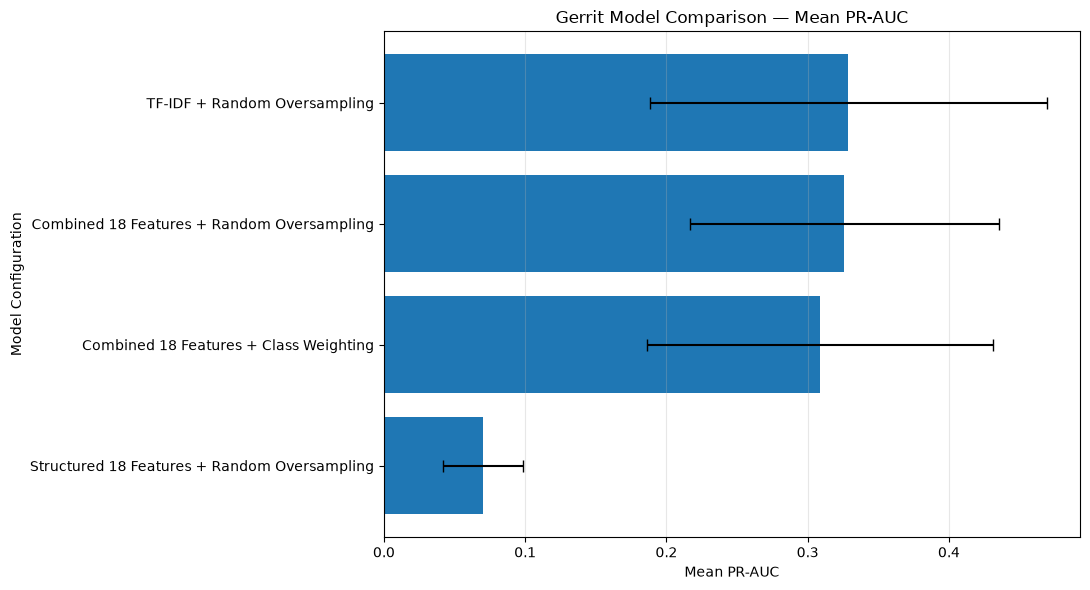

In [13]:
plot_df = summary_df.sort_values(
    "Mean_PR_AUC",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["Model"],
    plot_df["Mean_PR_AUC"],
    xerr=plot_df["Std_PR_AUC"],
    capsize=4
)

plt.xlabel("Mean PR-AUC")
plt.ylabel("Model Configuration")
plt.title("Gerrit Model Comparison — Mean PR-AUC")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,Mean_Precision,Mean_Recall,Mean_F1,Mean_PR_AUC,Mean_Balanced_Accuracy
Model,,,,,
TF-IDF + Random Oversampling,0.3312,0.3876,0.3424,0.3287,0.6759
Combined 18 Features + Random Oversampling,0.3133,0.3769,0.3324,0.3259,0.6697
Combined 18 Features + Class Weighting,0.2794,0.3615,0.3096,0.3087,0.6605
Structured 18 Features + Random Oversampling,0.0525,0.7543,0.0982,0.0702,0.5982


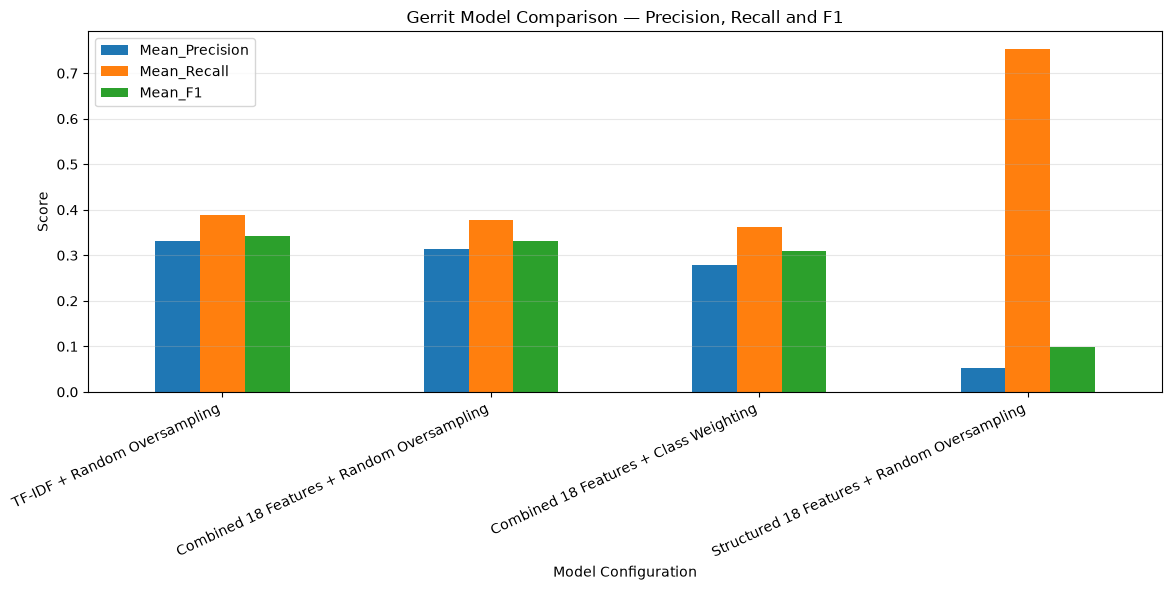

In [14]:
comparison_metrics = summary_df[
    [
        "Model",
        "Mean_Precision",
        "Mean_Recall",
        "Mean_F1",
        "Mean_PR_AUC",
        "Mean_Balanced_Accuracy"
    ]
].set_index("Model")

display(comparison_metrics.round(4))

comparison_metrics[
    ["Mean_Precision", "Mean_Recall", "Mean_F1"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Gerrit Model Comparison — Precision, Recall and F1")
plt.ylabel("Score")
plt.xlabel("Model Configuration")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
OUTPUT_PATH = (
    PROJECT_ROOT / "data" / "gerrit" /
    "couchbase_java_client" / "features"
)

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

fold_results_path = OUTPUT_PATH / "final_model_fold_results.csv"
summary_results_path = OUTPUT_PATH / "final_model_comparison_summary.csv"

results_df.to_csv(fold_results_path, index=False)
summary_df.to_csv(summary_results_path, index=False)

print("Results saved successfully:")
print(fold_results_path)
print(summary_results_path)

Results saved successfully:
/Users/mustafaahmed/Documents/Security Code Review Analysis/data/gerrit/couchbase_java_client/features/final_model_fold_results.csv
/Users/mustafaahmed/Documents/Security Code Review Analysis/data/gerrit/couchbase_java_client/features/final_model_comparison_summary.csv


In [16]:
print("=" * 60)
print("GERRIT FINAL MODEL COMPARISON")
print("=" * 60)

print("\nDataset:")
print(f"Total modelling revisions: {len(df_model)}")
print(f"Unique reviews: {groups.nunique()}")
print(f"Security-related revisions: {(y == 0).sum()}")
print(f"Not security-related revisions: {(y == 1).sum()}")

print("\nEvaluation:")
print("Method: 5-fold Stratified Group Cross-Validation")
print("Grouping: review_number")
print("Positive class: Security-related (original label 0)")
print("Imbalance handling: Random oversampling or class weighting")
print("Oversampling applied to training folds only.")

print("\nBest model by mean PR-AUC:")
print(best_model["Model"])
print(f"Mean PR-AUC: {best_model['Mean_PR_AUC']:.4f}")
print(f"Mean F1: {best_model['Mean_F1']:.4f}")
print(f"Mean Recall: {best_model['Mean_Recall']:.4f}")
print(f"Mean Precision: {best_model['Mean_Precision']:.4f}")

print("\n" + "=" * 60)

GERRIT FINAL MODEL COMPARISON

Dataset:
Total modelling revisions: 1774
Unique reviews: 808
Security-related revisions: 71
Not security-related revisions: 1703

Evaluation:
Method: 5-fold Stratified Group Cross-Validation
Grouping: review_number
Positive class: Security-related (original label 0)
Imbalance handling: Random oversampling or class weighting
Oversampling applied to training folds only.

Best model by mean PR-AUC:
TF-IDF + Random Oversampling
Mean PR-AUC: 0.3287
Mean F1: 0.3424
Mean Recall: 0.3876
Mean Precision: 0.3312



In [17]:
best_model_name = "TF-IDF + Random Oversampling"

best_fold_results = results_df[
    results_df["Model"] == best_model_name
].copy()

best_fold_results = best_fold_results.sort_values("Fold")

display(
    best_fold_results[
        [
            "Fold",
            "Precision",
            "Recall",
            "F1",
            "PR_AUC",
            "Balanced Accuracy"
        ]
    ].round(4)
)

,Fold,Precision,Recall,F1,PR_AUC,Balanced Accuracy
0,1,0.2353,0.2857,0.2581,0.2504,0.6238
4,2,0.5000,0.2857,0.3636,0.2573,0.6370
8,3,0.2632,0.3846,0.3125,0.2093,0.6717
12,4,0.3448,0.6250,0.4444,0.5565,0.7847
16,5,0.3125,0.3571,0.3333,0.3699,0.6623


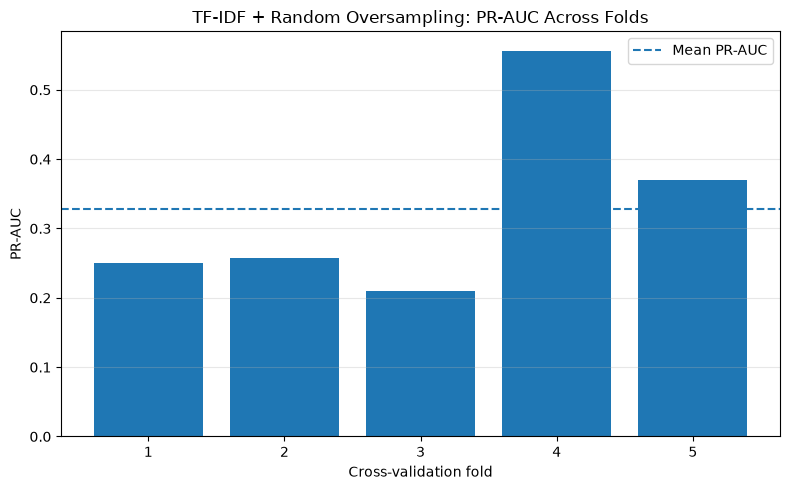

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(
    best_fold_results["Fold"].astype(str),
    best_fold_results["PR_AUC"]
)

plt.axhline(
    best_fold_results["PR_AUC"].mean(),
    linestyle="--",
    label="Mean PR-AUC"
)

plt.xlabel("Cross-validation fold")
plt.ylabel("PR-AUC")
plt.title("TF-IDF + Random Oversampling: PR-AUC Across Folds")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

oof_predictions = np.zeros(len(df_model), dtype=int)
oof_probabilities = np.zeros(len(df_model), dtype=float)
oof_fold_numbers = np.zeros(len(df_model), dtype=int)

print("Out-of-fold prediction storage initialized.")

Out-of-fold prediction storage initialized.


In [ ]:
for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups),
    start=1
):
    print(f"Generating predictions for fold {fold_number}...")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    text_train = texts.iloc[train_idx]
    text_valid = texts.iloc[valid_idx]

    y_train_binary = (y.iloc[train_idx] == 0).astype(int)

    structured_train, structured_valid = (
        prepare_structured_features(X_train, X_valid)
    )

    tfidf_train, tfidf_valid = prepare_tfidf_features(
        text_train,
        text_valid
    )

    sampler = RandomOverSampler(random_state=42)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        tfidf_train,
        y_train_binary
    )

    model = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_resampled, y_train_resampled)

    fold_predictions = model.predict(tfidf_valid)
    fold_probabilities = model.predict_proba(tfidf_valid)[:, 1]

    oof_predictions[valid_idx] = fold_predictions
    oof_probabilities[valid_idx] = fold_probabilities
    oof_fold_numbers[valid_idx] = fold_number

print("\nOut-of-fold predictions generated successfully.")

Generating predictions for fold 1...
Generating predictions for fold 2...
Generating predictions for fold 3...
Generating predictions for fold 4...
Generating predictions for fold 5...

Out-of-fold predictions generated successfully.


In [21]:
oof_df = df_model[
    [
        "review_number",
        "revision_number",
        "commit_id",
        "security_label"
    ]
].copy()

oof_df["actual_security_related"] = (
    oof_df["security_label"] == 0
).astype(int)

oof_df["predicted_security_related"] = oof_predictions
oof_df["security_probability"] = oof_probabilities
oof_df["validation_fold"] = oof_fold_numbers

print("Out-of-fold dataset shape:", oof_df.shape)

display(oof_df.head(10))

Out-of-fold dataset shape: (1774, 8)


,review_number,revision_number,commit_id,security_label,actual_security_related,predicted_security_related,security_probability,validation_fold
0,12027,1,634fb3ea0b12e60b8d8b27d9aa3f36d5f394d83e,1,0,0,0.279992,4
1,12050,1,dd6454bd6574a9337528281df912f51a9fda52ad,1,0,0,0.044585,2
2,12050,2,8c338944a8c4e5e068db7009c41be5cbcb8b72f1,1,0,0,0.044374,2
3,12050,3,eddbfeac3b56721994ab0bdc7a63ded3aec6bb1a,1,0,0,0.147370,2
4,12050,4,ced15bea74bce3e242865edd18d5cb1370d2eecb,1,0,0,0.167131,2
5,12050,5,8356f7a9c81a3e46663165dd47a4135d7b68cb17,1,0,0,0.121405,2
6,12051,1,a0bf87083125954cf3def1001d3b4b8744dd6421,1,0,0,0.147626,1
7,12096,1,6e26cb4174a414f262b5bc542aa309557c4d9f94,1,0,0,0.135808,1
9,12148,1,2aa78d5e51abefbc1a557e0f6383e4d0c66eba36,1,0,0,0.132293,2
10,12149,1,e8a5e07c1c687c23f2de2efe9ccc23cd02f906c5,1,0,0,0.168781,4


In [22]:
print("Total modelling revisions:", len(df_model))
print("Stored predictions:", len(oof_df))
print(
    "Missing predictions:",
    (oof_df["validation_fold"] == 0).sum()
)
print(
    "Number of validation folds:",
    oof_df["validation_fold"].nunique()
)

print("\nPredictions by fold:")
print(
    oof_df["validation_fold"]
    .value_counts()
    .sort_index()
)

assert len(oof_df) == len(df_model)
assert (oof_df["validation_fold"] != 0).all()
assert oof_df["validation_fold"].nunique() == 5

print("\nPrediction coverage verified.")

Total modelling revisions: 1774
Stored predictions: 1774
Missing predictions: 0
Number of validation folds: 5

Predictions by fold:
validation_fold
1    355
2    355
3    353
4    358
5    353
Name: count, dtype: int64

Prediction coverage verified.


In [23]:
y_true = oof_df["actual_security_related"]
y_pred = oof_df["predicted_security_related"]

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix")
print("----------------")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nBreakdown:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix
----------------
[[1642   61]
 [  43   28]]

Breakdown:
True Negatives: 1642
False Positives: 61
False Negatives: 43
True Positives: 28


In [24]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Not security-related",
            "Security-related"
        ],
        zero_division=0
    )
)

print("Overall PR-AUC:", round(
    average_precision_score(
        y_true,
        oof_df["security_probability"]
    ),
    4
))

print("Overall Balanced Accuracy:", round(
    balanced_accuracy_score(y_true, y_pred),
    4
))

                      precision    recall  f1-score   support

Not security-related       0.97      0.96      0.97      1703
    Security-related       0.31      0.39      0.35        71

            accuracy                           0.94      1774
           macro avg       0.64      0.68      0.66      1774
        weighted avg       0.95      0.94      0.94      1774

Overall PR-AUC: 0.2968
Overall Balanced Accuracy: 0.6793


In [25]:
false_positives = oof_df[
    (oof_df["actual_security_related"] == 0) &
    (oof_df["predicted_security_related"] == 1)
].copy()

false_positives = false_positives.sort_values(
    "security_probability",
    ascending=False
)

print("Number of false positives:", len(false_positives))

display(
    false_positives[
        [
            "review_number",
            "revision_number",
            "security_label",
            "security_probability",
            "validation_fold"
        ]
    ].head(20)
)

Number of false positives: 61


,review_number,revision_number,security_label,security_probability,validation_fold
2442,76638,2,1,0.946803,3
2439,76637,1,1,0.937630,1
642,32727,1,1,0.857215,2
2523,80570,2,1,0.842040,4
2404,75266,7,1,0.834504,5
691,34427,1,1,0.832243,4
2472,78197,1,1,0.829261,5
2403,75266,6,1,0.824888,5
689,34380,1,1,0.797098,1
687,34378,2,1,0.797098,1


In [26]:
false_negatives = oof_df[
    (oof_df["actual_security_related"] == 1) &
    (oof_df["predicted_security_related"] == 0)
].copy()

false_negatives = false_negatives.sort_values(
    "security_probability",
    ascending=True
)

print("Number of false negatives:", len(false_negatives))

display(
    false_negatives[
        [
            "review_number",
            "revision_number",
            "security_label",
            "security_probability",
            "validation_fold"
        ]
    ].head(20)
)

Number of false negatives: 43


,review_number,revision_number,security_label,security_probability,validation_fold
2219,67630,5,0,0.017615,1
1298,45796,1,0,0.032298,1
383,27790,2,0,0.040042,3
1300,45860,1,0,0.044682,1
2612,84365,1,0,0.049879,2
2388,75263,2,0,0.054313,4
1301,45860,2,0,0.055680,1
636,32589,11,0,0.059487,2
2210,67193,1,0,0.066742,3
640,32589,15,0,0.093440,2


In [27]:
true_positives = oof_df[
    (oof_df["actual_security_related"] == 1) &
    (oof_df["predicted_security_related"] == 1)
].copy()

true_positives = true_positives.sort_values(
    "security_probability",
    ascending=False
)

print("Number of true positives:", len(true_positives))

display(
    true_positives[
        [
            "review_number",
            "revision_number",
            "security_probability",
            "validation_fold"
        ]
    ].head(20)
)

Number of true positives: 28


,review_number,revision_number,security_probability,validation_fold
2228,68090,3,0.947317,4
625,32425,4,0.934115,5
2223,68089,1,0.929433,1
2197,66801,1,0.910759,4
1296,45572,1,0.861387,4
2377,73513,7,0.852974,5
2225,68089,3,0.847433,1
650,32994,6,0.844210,5
1303,45860,4,0.837713,1
2201,66801,5,0.825750,4


In [28]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:

    threshold_predictions = (
        oof_df["security_probability"] >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_true,
            threshold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            threshold_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            threshold_predictions,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            threshold_predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,Balanced Accuracy
0,0.2,0.1162,0.6479,0.1970,0.7212
1,0.3,0.1593,0.5070,0.2424,0.6977
2,0.4,0.2422,0.4366,0.3116,0.6898
3,0.5,0.3146,0.3944,0.3500,0.6793
4,0.6,0.4310,0.3521,0.3876,0.6664
5,0.7,0.5111,0.3239,0.3966,0.6555
6,0.8,0.5556,0.1408,0.2247,0.5681


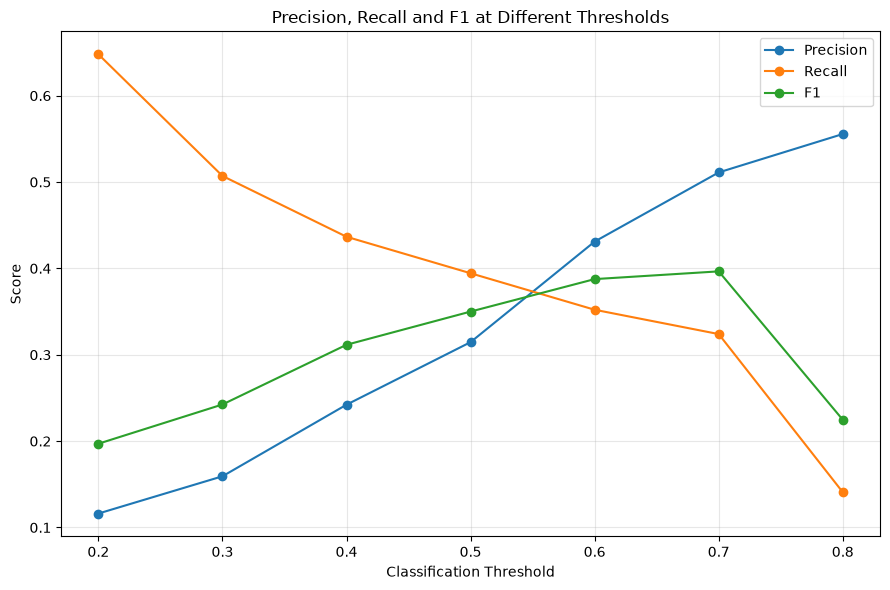

In [29]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
OOF_OUTPUT_PATH = (
    PROJECT_ROOT / "data" / "gerrit" /
    "couchbase_java_client" / "features"
)

OOF_OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

oof_df.to_csv(
    OOF_OUTPUT_PATH / "gerrit_oof_predictions.csv",
    index=False
)

false_positives.to_csv(
    OOF_OUTPUT_PATH / "gerrit_false_positives.csv",
    index=False
)

false_negatives.to_csv(
    OOF_OUTPUT_PATH / "gerrit_false_negatives.csv",
    index=False
)

true_positives.to_csv(
    OOF_OUTPUT_PATH / "gerrit_true_positives.csv",
    index=False
)

threshold_df.to_csv(
    OOF_OUTPUT_PATH / "gerrit_threshold_comparison.csv",
    index=False
)

print("Out-of-fold analysis files saved successfully.")

Out-of-fold analysis files saved successfully.


In [ ]:
import json

gerrit_details = pd.read_csv(DIFF_PATH)

gerrit_details = gerrit_details[
    [
        "review_number",
        "revision_number",
        "code_diff",
        "review_messages"
    ]
]

error_analysis_df = oof_df.merge(
    gerrit_details,
    on=["review_number", "revision_number"],
    how="left",
    validate="one_to_one"
)

error_analysis_df["prediction_type"] = np.select(
    [
        (error_analysis_df["actual_security_related"] == 1) &
        (error_analysis_df["predicted_security_related"] == 1),

        (error_analysis_df["actual_security_related"] == 0) &
        (error_analysis_df["predicted_security_related"] == 1),

        (error_analysis_df["actual_security_related"] == 1) &
        (error_analysis_df["predicted_security_related"] == 0)
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="True Negative"
)

print("Prediction type counts:")
display(error_analysis_df["prediction_type"].value_counts())

print("\nMissing code diffs:", error_analysis_df["code_diff"].isna().sum())
print("Missing review messages:", error_analysis_df["review_messages"].isna().sum())

display(error_analysis_df.head())

Prediction type counts:


prediction_type
True Negative     1642
False Positive      61
False Negative      43
True Positive       28
Name: count, dtype: int64


Missing code diffs: 0
Missing review messages: 0


,review_number,revision_number,commit_id,security_label,actual_security_related,predicted_security_related,security_probability,validation_fold,code_diff,review_messages,prediction_type
0,12027,1,634fb3ea0b12e60b8d8b27d9aa3f36d5f394d83e,1,0,0,0.279992,4,diff --git a/src/test/java/net/spy/memcached/M...,"[{""message_id"": ""6015f49d48eb9e0ca5c9800f5fc37...",True Negative
1,12050,1,dd6454bd6574a9337528281df912f51a9fda52ad,1,0,0,0.044585,2,diff --git a/build.xml b/build.xml\nindex 860a...,[],True Negative
2,12050,2,8c338944a8c4e5e068db7009c41be5cbcb8b72f1,1,0,0,0.044374,2,diff --git a/src/main/java/net/spy/memcached/M...,"[{""message_id"": ""5030f5f9921306a662d8dc1ad3517...",True Negative
3,12050,3,eddbfeac3b56721994ab0bdc7a63ded3aec6bb1a,1,0,0,0.147370,2,diff --git a/src/main/java/com/couchbase/clien...,"[{""message_id"": ""5eac3df10dc8f15d5f884220f87ac...",True Negative
4,12050,4,ced15bea74bce3e242865edd18d5cb1370d2eecb,1,0,0,0.167131,2,diff --git a/src/main/java/com/couchbase/clien...,"[{""message_id"": ""65f6cae68def4634be863be263c64...",True Negative


In [ ]:
import json

false_positive_samples = (
    error_analysis_df[
        error_analysis_df["prediction_type"] == "False Positive"
    ]
    .sort_values("security_probability", ascending=False)
    .head(5)
)

false_negative_samples = (
    error_analysis_df[
        error_analysis_df["prediction_type"] == "False Negative"
    ]
    .sort_values("security_probability", ascending=True)
    .head(5)
)

manual_review_samples = pd.concat(
    [false_positive_samples, false_negative_samples],
    ignore_index=True
)

print("Selected examples:")
display(
    manual_review_samples[
        [
            "review_number",
            "revision_number",
            "security_label",
            "actual_security_related",
            "predicted_security_related",
            "security_probability",
            "prediction_type"
        ]
    ]
)

print("\nNumber of selected false positives:", len(false_positive_samples))
print("Number of selected false negatives:", len(false_negative_samples))

Selected examples:


,review_number,revision_number,security_label,actual_security_related,predicted_security_related,security_probability,prediction_type
0,76638,2,1,0,1,0.946803,False Positive
1,76637,1,1,0,1,0.937630,False Positive
2,32727,1,1,0,1,0.857215,False Positive
3,80570,2,1,0,1,0.842040,False Positive
4,75266,7,1,0,1,0.834504,False Positive
5,67630,5,0,1,0,0.017615,False Negative
6,45796,1,0,1,0,0.032298,False Negative
7,27790,2,0,1,0,0.040042,False Negative
8,45860,1,0,1,0,0.044682,False Negative
9,84365,1,0,1,0,0.049879,False Negative



Number of selected false positives: 5
Number of selected false negatives: 5


In [ ]:
for _, row in manual_review_samples.iterrows():

    print("\n" + "=" * 90)
    print(f"Review Number: {row['review_number']}")
    print(f"Revision Number: {row['revision_number']}")
    print(f"Prediction Type: {row['prediction_type']}")
    print(f"Actual Security-Related: {row['actual_security_related']}")
    print(f"Predicted Security-Related: {row['predicted_security_related']}")
    print(f"Security Probability: {row['security_probability']:.4f}")
    print("=" * 90)

    print("\nREVIEW MESSAGES:")

    messages = json.loads(row["review_messages"])

    if messages:
        for message in messages:
            print(f"- Author: {message.get('author', 'Unknown')}")
            print(f"  Message: {message.get('message', '')}")
    else:
        print("No review messages available.")

    print("\nCODE DIFF:")

    diff = row["code_diff"]

    if isinstance(diff, str) and diff.strip():
        print(diff[:4000])

        if len(diff) > 4000:
            print("\n[Diff truncated for display. Full diff remains in the dataset.]")
    else:
        print("No code diff available.")


Review Number: 76638
Revision Number: 2
Prediction Type: False Positive
Actual Security-Related: 0
Predicted Security-Related: 1
Security Probability: 0.9468

REVIEW MESSAGES:
- Author: Michael Nitschinger
  Message: Change has been successfully cherry-picked as ddf666f78fa693d3cb2275052fb042bb92e46288 by Michael Nitschinger

CODE DIFF:
diff --git a/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java b/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
index a4d62b57a642fe2a468d0c971fd1c2d668997588..0ea20e3efac398cc9f87a597e826bc1149ab5770 100644
--- a/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
+++ b/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
@@ -68,6 +68,14 @@ public class PasswordAuthenticatorTest {
         cluster.disconnect();
     }
 
+    @Test
+    public void shouldOpenBucketWithShortcutOverload() {
+        Cluster cluster = Couchbase

In [ ]:
import re
import json

def extract_changed_files(diff):
    if not isinstance(diff, str):
        return []

    files = re.findall(r"^diff --git a/(.*?) b/", diff, flags=re.MULTILINE)
    return files


def extract_diff_summary(diff):
    if not isinstance(diff, str):
        return "No diff available"

    added = 0
    deleted = 0

    for line in diff.splitlines():
        if line.startswith("+++") or line.startswith("---"):
            continue
        if line.startswith("+"):
            added += 1
        elif line.startswith("-"):
            deleted += 1

    return f"+{added} additions / -{deleted} deletions"


summary_rows = []

for _, row in manual_review_samples.iterrows():

    messages = json.loads(row["review_messages"])

    message_text = " | ".join(
        message.get("message", "")
        for message in messages
        if message.get("message")
    )

    changed_files = extract_changed_files(row["code_diff"])

    summary_rows.append({
        "review_number": row["review_number"],
        "revision_number": row["revision_number"],
        "prediction_type": row["prediction_type"],
        "security_probability": round(row["security_probability"], 4),
        "changed_files": ", ".join(changed_files[:3]),
        "diff_summary": extract_diff_summary(row["code_diff"]),
        "review_message": message_text[:300]
    })

error_summary_df = pd.DataFrame(summary_rows)

display(error_summary_df)

,review_number,revision_number,prediction_type,security_probability,changed_files,diff_summary,review_message
0,76638,2,False Positive,0.9468,src/integration/java/com/couchbase/client/java...,+37 additions / -0 deletions,Change has been successfully cherry-picked as ...
1,76637,1,False Positive,0.9376,src/integration/java/com/couchbase/client/java...,+37 additions / -0 deletions,Uploaded patch set 1. | Patch Set 1: Verified+...
2,32727,1,False Positive,0.8572,src/main/java/com/couchbase/client/CouchbaseCo...,+29 additions / -3 deletions,
3,80570,2,False Positive,0.8420,src/integration/java/com/couchbase/client/java...,+39 additions / -9 deletions,Uploaded patch set 2. | Patch Set 2: Code-Revi...
4,75266,7,False Positive,0.8345,src/integration/java/com/couchbase/client/java...,+106 additions / -111 deletions,Uploaded patch set 7. | Patch Set 7: Verified+...
5,67630,5,False Negative,0.0176,pom.xml,+2 additions / -2 deletions,
6,45796,1,False Negative,0.0323,README.md,+5 additions / -1 deletions,Uploaded patch set 1. | Patch Set 1: Verified+...
7,27790,2,False Negative,0.0400,src/main/java/com/couchbase/client/CouchbaseCl...,+3 additions / -2 deletions,Change has been successfully cherry-picked as ...
8,45860,1,False Negative,0.0447,src/integration/java/com/couchbase/client/java...,+147 additions / -15 deletions,Uploaded patch set 1. | Patch Set 1: Verified+...
9,84365,1,False Negative,0.0499,src/main/java/com/couchbase/client/java/env/De...,+18 additions / -0 deletions,Uploaded patch set 1. | Patch Set 1:\n\nBuild ...


In [ ]:
for _, row in false_negative_samples.iterrows():

    print("\n" + "=" * 90)
    print(f"Review: {row['review_number']}")
    print(f"Revision: {row['revision_number']}")
    print(f"Security probability: {row['security_probability']:.4f}")
    print("=" * 90)

    print("\nREVIEW MESSAGES:")

    messages = json.loads(row["review_messages"])

    if messages:
        for message in messages:
            text = message.get("message", "").strip()
            if text:
                print("-", text)
    else:
        print("No review messages.")

    print("\nCODE DIFF:")

    diff = row["code_diff"]

    if isinstance(diff, str) and diff.strip():
        print(diff[:5000])

        if len(diff) > 5000:
            print("\n[Diff truncated. Full diff remains available in the dataset.]")
    else:
        print("No code diff available.")


Review: 67630
Revision: 5
Security probability: 0.0176

REVIEW MESSAGES:
No review messages.

CODE DIFF:
diff --git a/pom.xml b/pom.xml
index 7cc36c68c336384f609b7af6c1afbd6a62241980..946ad4ef5990131c138ef24fca29d158ea05fe5e 100644
--- a/pom.xml
+++ b/pom.xml
@@ -16,7 +16,7 @@
 
     <groupId>com.couchbase.client</groupId>
     <artifactId>java-client</artifactId>
-    <version>2.3.3</version>
+    <version>2.3.4-SNAPSHOT</version>
     <packaging>jar</packaging>
 
     <name>Couchbase Java SDK</name>
@@ -28,7 +28,7 @@
         <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
         <project.reporting.outputEncoding>UTF-8</project.reporting.outputEncoding>
 
-        <core.version>1.3.3</core.version>
+        <core.version>1.3.4-SNAPSHOT</core.version>
         <junit.version>4.12</junit.version>
         <mockito.version>1.10.19</mockito.version>
         <slf4j.version>1.7.7</slf4j.version>


Review: 45796
Revision: 1
Security probability: 0.0323

REVIEW MESSAGE

In [ ]:
remaining_false_negatives = false_negative_samples.iloc[3:]

for _, row in remaining_false_negatives.iterrows():

    print("\n" + "=" * 80)
    print(f"Review: {row['review_number']} | Revision: {row['revision_number']}")
    print(f"Security probability: {row['security_probability']:.4f}")
    print("=" * 80)

    print("\nREVIEW MESSAGES:")

    messages = json.loads(row["review_messages"])

    if messages:
        for message in messages:
            message_text = message.get("message", "").strip()
            if message_text:
                print("-", message_text)
    else:
        print("No review messages.")

    print("\nCODE DIFF:")

    diff = row["code_diff"]

    if isinstance(diff, str) and diff.strip():
        print(diff[:3500])

        if len(diff) > 3500:
            print("\n[Diff truncated.]")
    else:
        print("No code diff available.")


Review: 45860 | Revision: 1
Security probability: 0.0447

REVIEW MESSAGES:
- Uploaded patch set 1.
- Patch Set 1: Verified+1

Note: QueryTest doesn't entirely pass due to consistency problems after the initial flush. N1QL taking consistency parameters into account is not yet implemented.

CODE DIFF:
diff --git a/src/integration/java/com/couchbase/client/java/QueryTest.java b/src/integration/java/com/couchbase/client/java/QueryTest.java
index fa1f2cb0e392cce158c356a30cf32de7af969c99..1880292a53f975a7922c3d70861ac4b8c938fe5f 100644
--- a/src/integration/java/com/couchbase/client/java/QueryTest.java
+++ b/src/integration/java/com/couchbase/client/java/QueryTest.java
@@ -24,7 +24,9 @@ package com.couchbase.client.java;
 import com.couchbase.client.java.document.JsonDocument;
 import com.couchbase.client.java.document.json.JsonArray;
 import com.couchbase.client.java.document.json.JsonObject;
+import com.couchbase.client.java.query.PreparedQuery;
 import com.couchbase.client.java.query.Que

In [ ]:
row = error_analysis_df[
    (error_analysis_df["review_number"] == 84365) &
    (error_analysis_df["revision_number"] == 1)
].iloc[0]

print("Review:", row["review_number"])
print("Revision:", row["revision_number"])
print("Prediction:", row["prediction_type"])
print("Security probability:", round(row["security_probability"], 4))

print("\nREVIEW MESSAGES:")

messages = json.loads(row["review_messages"])

for message in messages:
    if message.get("message", "").strip():
        print("-", message["message"])

print("\nCODE DIFF:")
print(row["code_diff"][:5000])

Review: 84365
Revision: 1
Prediction: False Negative
Security probability: 0.0499

REVIEW MESSAGES:
- Uploaded patch set 1.
- Patch Set 1:

Build Started http://sdkbuilds.sc.couchbase.com/job/couchbase-java-client-test/221/
- Patch Set 1: Verified+1
- Patch Set 1: Verified-1

Build Failed 

http://sdkbuilds.sc.couchbase.com/job/couchbase-java-client-test/221/ : FAILURE
- Patch Set 1: Code-Review+2
- Patch Set 1:

Build Started http://sdkbuilds.sc.couchbase.com/job/couchbase-java-client-test/223/
- Patch Set 1: Verified+1

Build Successful 

http://sdkbuilds.sc.couchbase.com/job/couchbase-java-client-test/223/ : SUCCESS

CODE DIFF:
diff --git a/src/main/java/com/couchbase/client/java/env/DefaultCouchbaseEnvironment.java b/src/main/java/com/couchbase/client/java/env/DefaultCouchbaseEnvironment.java
index 2bded44d3d7345e419c327a209bd0ba76082b853..cecc7f50598120eb0fb32f9e462f2e83b84b0304 100644
--- a/src/main/java/com/couchbase/client/java/env/DefaultCouchbaseEnvironment.java
+++ b/src/mai

In [ ]:
for _, row in false_positive_samples.iterrows():

    print("\n" + "=" * 80)
    print(f"Review: {row['review_number']}")
    print(f"Revision: {row['revision_number']}")
    print(f"Security probability: {row['security_probability']:.4f}")
    print("=" * 80)

    print("\nREVIEW MESSAGES:")

    messages = json.loads(row["review_messages"])

    if messages:
        for message in messages:
            message_text = message.get("message", "").strip()
            if message_text:
                print("-", message_text)
    else:
        print("No review messages.")

    print("\nCODE DIFF:")

    diff = row["code_diff"]

    if isinstance(diff, str) and diff.strip():
        print(diff[:3500])

        if len(diff) > 3500:
            print("\n[Diff truncated.]")
    else:
        print("No code diff available.")


Review: 76638
Revision: 2
Security probability: 0.9468

REVIEW MESSAGES:
- Change has been successfully cherry-picked as ddf666f78fa693d3cb2275052fb042bb92e46288 by Michael Nitschinger

CODE DIFF:
diff --git a/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java b/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
index a4d62b57a642fe2a468d0c971fd1c2d668997588..0ea20e3efac398cc9f87a597e826bc1149ab5770 100644
--- a/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
+++ b/src/integration/java/com/couchbase/client/java/auth/PasswordAuthenticatorTest.java
@@ -68,6 +68,14 @@ public class PasswordAuthenticatorTest {
         cluster.disconnect();
     }
 
+    @Test
+    public void shouldOpenBucketWithShortcutOverload() {
+        Cluster cluster = CouchbaseCluster.create(ctx.seedNode());
+        cluster.authenticate(username, password);
+        cluster.openBucket(ctx.bucketName());
+        clu

In [ ]:
remaining_false_positives = false_positive_samples.iloc[3:]

for _, row in remaining_false_positives.iterrows():

    print("\n" + "=" * 80)
    print(f"Review: {row['review_number']}")
    print(f"Revision: {row['revision_number']}")
    print(f"Security probability: {row['security_probability']:.4f}")
    print("=" * 80)

    print("\nREVIEW MESSAGES:")

    messages = json.loads(row["review_messages"])

    if messages:
        for message in messages:
            message_text = message.get("message", "").strip()
            if message_text:
                print("-", message_text)
    else:
        print("No review messages.")

    print("\nCODE DIFF:")

    diff = row["code_diff"]

    if isinstance(diff, str) and diff.strip():
        print(diff[:3500])

        if len(diff) > 3500:
            print("\n[Diff truncated.]")
    else:
        print("No code diff available.")


Review: 80570
Revision: 2
Security probability: 0.8420

REVIEW MESSAGES:
- Uploaded patch set 2.
- Patch Set 2: Code-Review+2 Verified+1

CODE DIFF:
diff --git a/src/integration/java/com/couchbase/client/java/BucketClosingTest.java b/src/integration/java/com/couchbase/client/java/BucketClosingTest.java
index 1d3376795020468292496da8e298df7faf30f292..8763f09a4c6c75058bf3528b793fe94d8e9d57a6 100644
--- a/src/integration/java/com/couchbase/client/java/BucketClosingTest.java
+++ b/src/integration/java/com/couchbase/client/java/BucketClosingTest.java
@@ -31,7 +31,12 @@ public class BucketClosingTest extends ClusterDependentTest {
 
   @Test(expected = BucketClosedException.class)
   public void shouldPreventSyncCloseBucketThenSyncGet() {
-    Bucket bucket = cluster().openBucket(bucketName(), password());
+    Bucket bucket;
+    if (ctx.rbacEnabled()) {
+      bucket = cluster().openBucket(bucketName());
+    } else {
+      bucket = cluster().openBucket(bucketName(), password());
+    }


In [ ]:
row = error_analysis_df[
    (error_analysis_df["review_number"] == 75266) &
    (error_analysis_df["revision_number"] == 7)
].iloc[0]

print("Review:", row["review_number"])
print("Revision:", row["revision_number"])
print("Prediction:", row["prediction_type"])
print("Security probability:", round(row["security_probability"], 4))

print("\nREVIEW MESSAGES:")

messages = json.loads(row["review_messages"])

for message in messages:
    if message.get("message", "").strip():
        print("-", message["message"])

print("\nCODE DIFF:")
print(row["code_diff"][:5000])

Review: 75266
Revision: 7
Prediction: False Positive
Security probability: 0.8345

REVIEW MESSAGES:
- Uploaded patch set 7.
- Patch Set 7: Verified+1

All changes are done as per comments except one -  I'll leave user type as string to allow flexibility, as the server side may have changes.
- Patch Set 7: Code-Review+2

CODE DIFF:
diff --git a/src/integration/java/com/couchbase/client/java/ClusterManagerTest.java b/src/integration/java/com/couchbase/client/java/ClusterManagerTest.java
index e39bc2ea1b9e9a8867506e2f82249f840356a0b5..5fa144c1b6b4af6c6790ed4f04f84fe20fdc4b80 100644
--- a/src/integration/java/com/couchbase/client/java/ClusterManagerTest.java
+++ b/src/integration/java/com/couchbase/client/java/ClusterManagerTest.java
@@ -20,26 +20,20 @@ import static org.junit.Assert.assertEquals;
 import static org.junit.Assert.assertNotNull;
 import static org.junit.Assert.assertTrue;
 
-import java.util.Collections;
 import java.util.HashSet;
 import java.util.List;
 import java.util.Se